In [2]:
import numpy as np
import networkx as nx
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

In [3]:
class basisStates:
    def __init__(self, L):
        self.L = L
        self.dim = 2**L

    def state(self, index):
        return format(index, f"0{self.L}b")

    def getIndex(self, state):
        return int(state, 2)
    
    def getAllBasisStates(self):
        return [self.state(i) for i in range(self.dim)]
    
    def x(self, index, site):
        if index is None:
            return None

        operated_state = self.state(index)

        flipped_bit = str(1 - int(operated_state[site]))

        new_state = operated_state[:site] + flipped_bit + operated_state[site+1:]
        
        return self.getIndex(new_state)
    
    def p(self, index, site):
        if index is None:
            return None

        operated_state = self.state(index)
    
        if operated_state[site] == '1':
            return None
        else:
            return index

    def pxp(self, index, site):

        new_index = self.p(index, (site - 1) % self.L)

        if new_index is None:
            return None

        new_index = self.p(new_index, (site + 1) % self.L)

        if new_index is None:
            return None

        new_index = self.x(new_index, site)

        return new_index


### Task 1

- Generate sparse matrix representation of the Hamiltonian H
- Analyze the structure of this Hamiltonian for a few system sizes L by drawing the adjacency graph of the matrix

In [20]:
state = basisStates(L=3) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [21]:
print(H)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 6 stored elements and shape (8, 8)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 4)	1.0
  (1, 0)	1.0
  (2, 0)	1.0
  (4, 0)	1.0


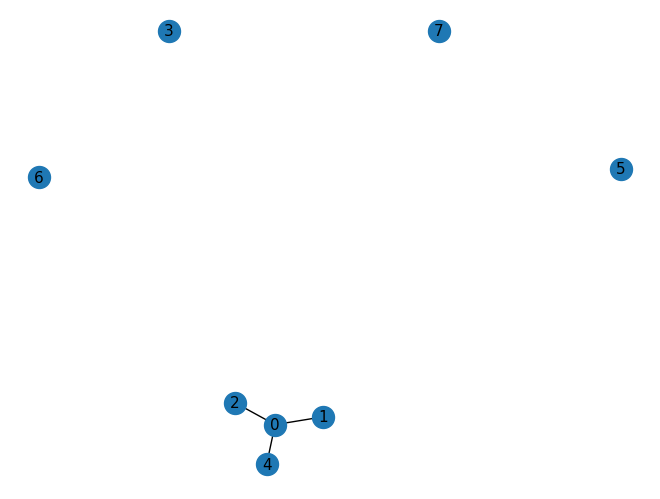

In [22]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

In [59]:
state = basisStates(L=4) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [60]:
print(H)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16 stored elements and shape (16, 16)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 4)	1.0
  (0, 8)	1.0
  (1, 0)	1.0
  (1, 5)	1.0
  (2, 0)	1.0
  (2, 10)	1.0
  (4, 0)	1.0
  (4, 5)	1.0
  (5, 1)	1.0
  (5, 4)	1.0
  (8, 0)	1.0
  (8, 10)	1.0
  (10, 2)	1.0
  (10, 8)	1.0


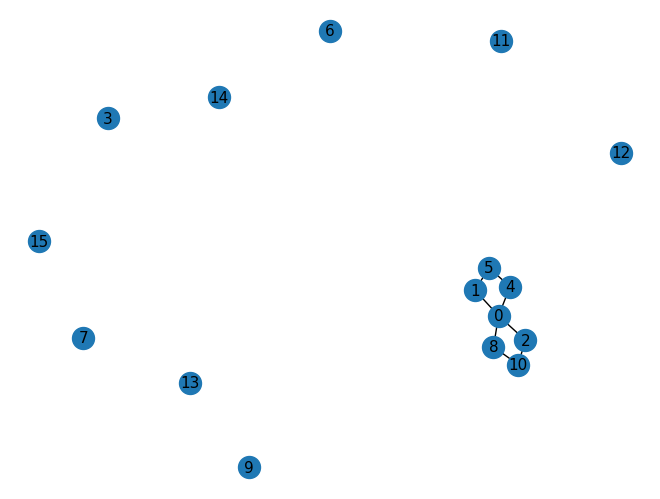

In [25]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

In [61]:
blocks = list(nx.connected_components(G)) # looking at all the blocks when L = 4

biggest_block = max(blocks, key=len) # Taking the biggest block

print(blocks)
print(biggest_block)

H_biggest_block = H[list(biggest_block), :][:, list(biggest_block)]

print(H_biggest_block)

[{0, 1, 2, 4, 5, 8, 10}, {3}, {6}, {7}, {9}, {11}, {12}, {13}, {14}, {15}]
{0, 1, 2, 4, 5, 8, 10}
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16 stored elements and shape (7, 7)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 3)	1.0
  (0, 5)	1.0
  (1, 0)	1.0
  (1, 4)	1.0
  (2, 0)	1.0
  (2, 6)	1.0
  (3, 0)	1.0
  (3, 4)	1.0
  (4, 1)	1.0
  (4, 3)	1.0
  (5, 0)	1.0
  (5, 6)	1.0
  (6, 2)	1.0
  (6, 5)	1.0


In [62]:
H_biggest_block.toarray()

array([[0., 1., 1., 1., 0., 1., 0.],
       [1., 0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1., 0., 0.],
       [0., 1., 0., 1., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 1., 0.]])

In [34]:
state = basisStates(L=5) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

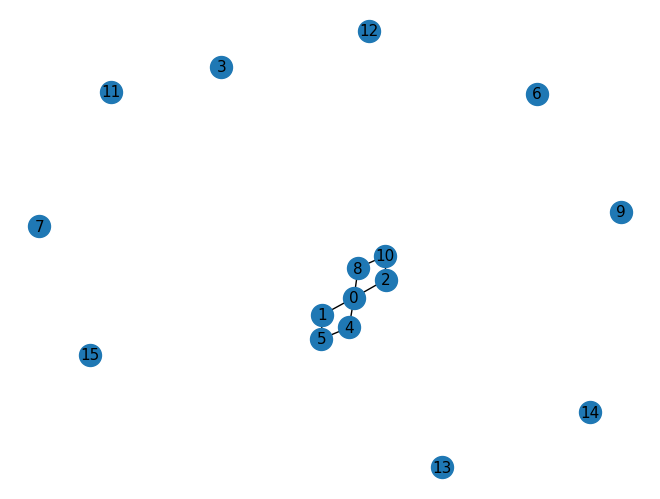

In [37]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

### Task 2

- Create a dense matrix version of the biggest block of the Hamiltonian and fully diagonalize it. 
- Later use as reference for benchmarking the polynomial filtering code.

In [65]:
state = basisStates(L=16) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [66]:
G = nx.from_scipy_sparse_array(H)

blocks = list(nx.connected_components(G)) # looking at all the blocks when L = 4

biggest_block = max(blocks, key=len) # Taking the biggest block

H_biggest_block = H[list(biggest_block), :][:, list(biggest_block)]

### Task 3

- The model is translation invariant. Create a basis of symmetrized momentum states (using only the restricted basis of the biggest block) to block diagonalize the biggest block in momentum sectors with moment k. 

- Check that you recover all eigenvalues obtained in Task 2.

### Task 4

- Calculate all eigenvectors the $k = 0$ block. 
- For each eigenvector, create a representation of the vector in the full basis. in binary counting order. 
- Use this representation to calculate the entropy of entanglement across a cut in the middle of the system by simple reshaping and calculating a singular value decomposition (SVD) of the resulting matrix. (Ulrich Schollwöck’s lecture notes arXiv:1008.3477 leading up to Eq. (25) for the exact procedure.)
- Calculate the entanglement entropy of every eigenvector and plot them against the corresponding eigenvalue. 

In the end a structure similar to Fig. (3a) in Phys. Rev. B 98, 155134
(2018) should be seen. Quantum many-body scar states are identified by an atypically low entanglement entropy in the middle of the spectrum.


### Task 5

- Using a sparse matrix representation of the $k = 0$ block $H_{k=0}$, write a function to apply a Chebyshev polynomial of this block to a vector, i.e. to calculate $x' = p(H_{k=0})x$. 

- Plug this function into scipy.sparse.linalg.eigsh (use the LinearOperator interface) to calculate exact eigenvectors of $H_{k=0}$ in the middle of the spectrum. 

- Try to find scar states with this procedure by choosing a polynomial which targets a specific eigenvalue (cf. script, essentially expand the delta function at the target value in terms of Chebyshev polynomials). 

- Calculate several (e.g. 20) eigenpairs close to a target and calculate and plot the entanglement entropy of each eigenvector. 

- Report the highest system sizes reached.